# Chapitre 2 - Cours 1 : Données d'entraînement et architecture transformer

Pourquoi deux modèles de fondation de même taille se comportent-ils si différemment ?
Le chapitre 2 du livre ramène ces différences à quelques **décisions de conception** :
les données d'entraînement, l'architecture et la taille du modèle, le post-entraînement,
et enfin la manière d'**échantillonner** les sorties. Ce premier notebook traite les deux
premières :

- section *Training Data* (avec *Multilingual Models* et *Domain-Specific Models*) :
  d'où viennent les données, qui y est représenté, et ce que cela coûte en tokens ;
- section *Model Architecture*, sous-section *Transformer architecture* : du seq2seq au
  transformer, le mécanisme d'attention (que l'on code à la main en numpy puis que l'on
  confronte aux vrais GPT-2 et Qwen2.5), les cartes d'attention réelles et le bloc
  transformer.

**Plan.** 1. Un modèle ne vaut que ses données ; 2. Qui est représenté dans le web ?
3. Le coût caché des langues ; 4. Modèles spécialisés ; 5. Du seq2seq au transformer ;
6. L'attention pas à pas ; 7. Multi-têtes : vérification sur GPT-2 et Qwen2.5 ;
8. Ce que regardent les têtes ; 9. Le bloc transformer ; Synthèse.

Tous les calculs de ce notebook tournent sur CPU (GPT-2 et Qwen2.5-0.5B en float32).

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tiktoken
import torch
from transformers import AutoTokenizer

from aie import llm
from aie import ch02_modeles as m
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
rng = np.random.default_rng(0)
torch.set_num_threads(8)
pd.set_option("display.precision", 2)

## 1. Un modèle ne vaut que ses données (section *Training Data*)

Un modèle n'apprend que ce qu'il voit : sans vietnamien dans ses données, il ne
traduira pas vers le vietnamien. Or réunir des données pour un modèle de plusieurs
milliards de paramètres coûte cher, si bien que les développeurs utilisent surtout ce
qui est **disponible** plutôt que ce qui serait **idéal**. La source dominante est
**Common Crawl**, une association qui explore le web (de l'ordre de 2 à 3 milliards de
pages par mois en 2022-2023), et sa version nettoyée par Google, **C4**. Leur qualité
est inégale : désinformation, pièges à clics, contenus haineux y côtoient Wikipédia.

D'où des **filtres heuristiques** (GPT-2 n'a gardé que les liens Reddit ayant reçu au
moins trois votes positifs), puis, de plus en plus, une **curation** ciblée par langue
ou par domaine. Plus de données n'est pas toujours mieux : le livre cite un modèle de
1,3 milliard de paramètres entraîné sur seulement 7 milliards de tokens de code de haute
qualité qui dépasse des modèles bien plus gros (Gunasekar et al., 2023). Le chapitre 8
reviendra sur l'ingénierie des données ; le schéma ci-dessous situe les étapes.

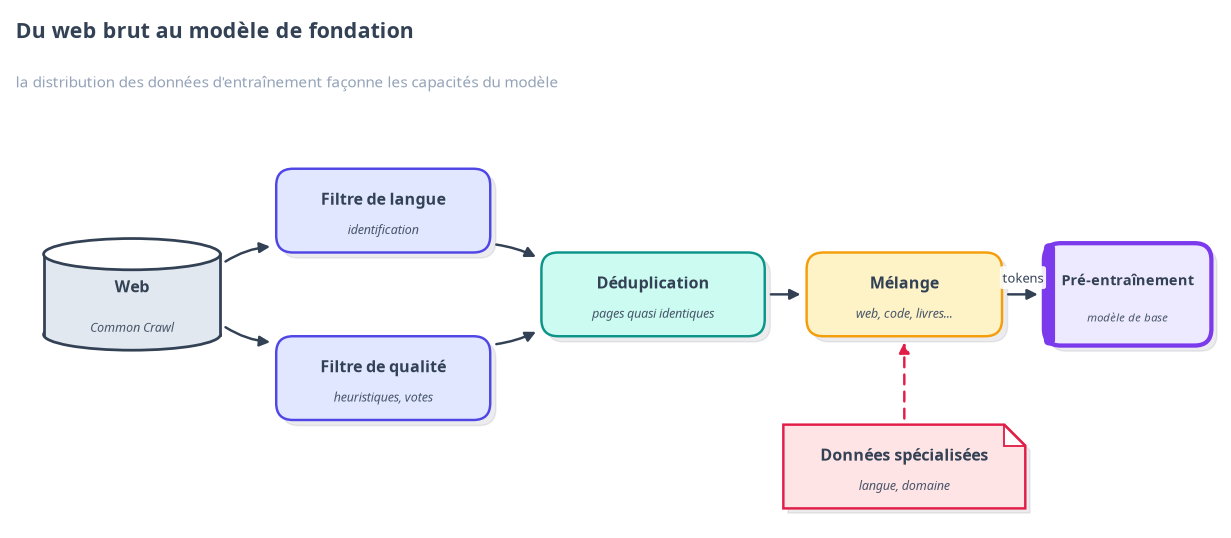

In [2]:
d = Diagram(13, 4.6, title="Du web brut au modèle de fondation",
            subtitle="la distribution des données d'entraînement façonne les capacités du modèle")
d.box("web", 1.3, 2.5, "Web", sub="Common Crawl", color=SLATE, kind="db", w=1.9, h=1.2)
d.box("lang", 4.0, 3.4, "Filtre de langue", sub="identification", color=INDIGO, w=2.3)
d.box("qual", 4.0, 1.6, "Filtre de qualité", sub="heuristiques, votes", color=INDIGO, w=2.3)
d.box("dedup", 6.9, 2.5, "Déduplication", sub="pages quasi identiques", color=TEAL, w=2.4)
d.box("mix", 9.6, 2.5, "Mélange", sub="web, code, livres...", color=AMBER, w=2.1)
d.box("spec", 9.6, 0.65, "Données spécialisées", sub="langue, domaine", color=ROSE, kind="doc", w=2.6, h=0.9)
d.box("model", 12.0, 2.5, "Pré-entraînement", sub="modèle de base", color=VIOLET, kind="model", w=1.8, h=1.1,
      fontsize=9.5)
d.arrow("web", "lang", rad=-0.15)
d.arrow("web", "qual", rad=0.15)
d.arrow("lang", "dedup", rad=-0.1)
d.arrow("qual", "dedup", rad=0.1)
d.arrow("dedup", "mix")
d.arrow("spec", "mix", style="dashed", color=ROSE)
d.arrow("mix", "model", "tokens")
d.show()

> **À retenir.** Les capacités d'un modèle reflètent la distribution de ses données :
> ce qui est rare ou absent du corpus (une langue, un domaine, une tâche) sera mal
> maîtrisé, quelle que soit la taille du modèle.

## 2. Modèles multilingues : qui est représenté dans le web ? (section *Multilingual Models*)

L'anglais représente près de **46 %** de Common Crawl, huit fois plus que la deuxième
langue (le russe, 6 %). Le livre compare la part de chaque langue dans la population
mondiale à sa part dans Common Crawl ; si l'on note $\pi_\ell$ la part des locuteurs de
la langue $\ell$ et $c_\ell$ sa part du corpus, le ratio
$$\rho_\ell = \frac{\pi_\ell}{c_\ell}$$
vaudrait 1 pour une représentation « équitable ». Un ratio de 100 signifie que la langue
est cent fois moins présente dans le corpus que dans le monde. Les langues absentes de la
liste des langues à plus de 1 % sont dites **peu dotées** (*low-resource*).

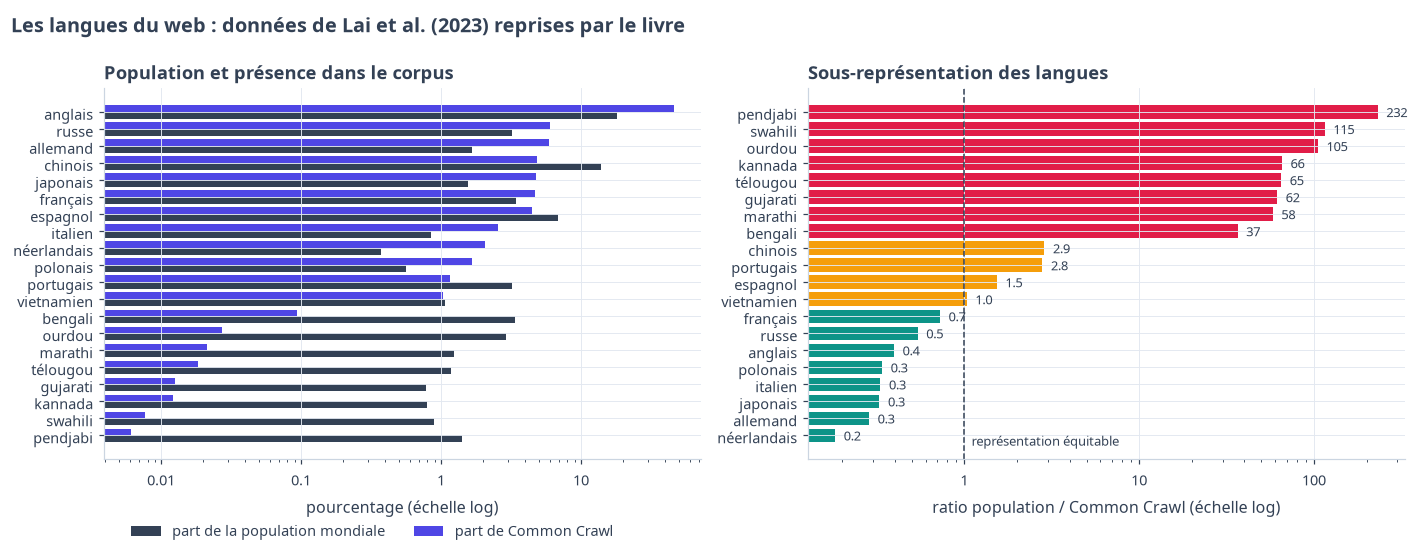

In [3]:
cc = m.common_crawl_table()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
y = np.arange(len(cc))
ax.barh(y + 0.2, cc["pop_pct"], height=0.4, color=SLATE, label="part de la population mondiale")
ax.barh(y - 0.2, cc["cc_pct"], height=0.4, color=INDIGO, label="part de Common Crawl")
ax.set_yticks(y, cc["langue"]); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_xlabel("pourcentage (échelle log)"); m.plain_log_axis(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2)
ax.set_title("Population et présence dans le corpus")
ax = axes[1]
srt = cc.sort_values("ratio_pop_cc")
colors = [TEAL if r < 1 else (AMBER if r < 10 else ROSE) for r in srt["ratio_pop_cc"]]
ax.barh(srt["langue"], srt["ratio_pop_cc"], color=colors)
ax.axvline(1, color=SLATE, ls="--", lw=1); ax.set_xscale("log")
ax.text(1.1, -0.6, "représentation équitable", fontsize=8.5, color=SLATE)
for yy, r in enumerate(srt["ratio_pop_cc"]):
    ax.text(r * 1.12, yy, f"{r:.1f}" if r < 10 else f"{r:.0f}", va="center", fontsize=8.5)
ax.set_xlabel("ratio population / Common Crawl (échelle log)"); m.plain_log_axis(ax)
ax.set_title("Sous-représentation des langues")
finish(fig, "Les langues du web : données de Lai et al. (2023) reprises par le livre")
plt.show()

Le pendjabi (113 millions de locuteurs) est plus de 200 fois sous-représenté, et les
langues les moins représentées (télougou, marathi, pendjabi) sont précisément celles où
GPT-4 obtient ses plus mauvais scores sur MMLU d'après le livre. La sous-représentation
n'explique pas tout (la structure d'une langue et la culture qu'elle porte jouent aussi),
et **traduire vers l'anglais** n'est pas une solution miracle : il faut un modèle qui
comprenne déjà la langue source, et la traduction perd de l'information (les pronoms
vietnamiens encodent la relation entre interlocuteurs, que « I » et « you » écrasent).

> **À retenir.** Le français est plutôt bien loti (4,7 % de Common Crawl, ratio proche
> de 1), mais des langues parlées par des centaines de millions de personnes sont
> quasiment absentes des corpus : un modèle généraliste y sera nettement moins bon.

## 3. Le coût caché des langues : tokens par langue

Au-delà de la qualité, le livre souligne un effet très concret : la **latence** et le
**coût** d'une requête sont proportionnels au nombre de tokens, et ce nombre dépend de
la langue. Sur le jeu de données MASSIVE, la longueur médiane d'un même énoncé est de 7
tokens en anglais, 32 en hindi et 72 en birman avec le tokenizer de GPT-4.

Mesurons-le nous-mêmes sur un petit **corpus parallèle** rédigé pour ce cours : les six
mêmes phrases dans 18 langues (`m.PARALLEL_CORPUS`), découpées par quatre tokenizers :

| tokenizer | modèle | vocabulaire |
|---|---|---|
| `gpt2` | GPT-2 (2019) | 50 257 |
| `cl100k_base` | GPT-4 | 100 277 |
| `o200k_base` | GPT-4o | 200 019 |
| Qwen2.5 | Qwen2.5 (2024) | 151 665 |

Pour chaque langue $\ell$ et chaque tokenizer, on calcule le **ratio de fertilité**
$r_\ell = n_\ell / n_{\text{en}}$ : le nombre de tokens pour dire la même chose, rapporté
à l'anglais.

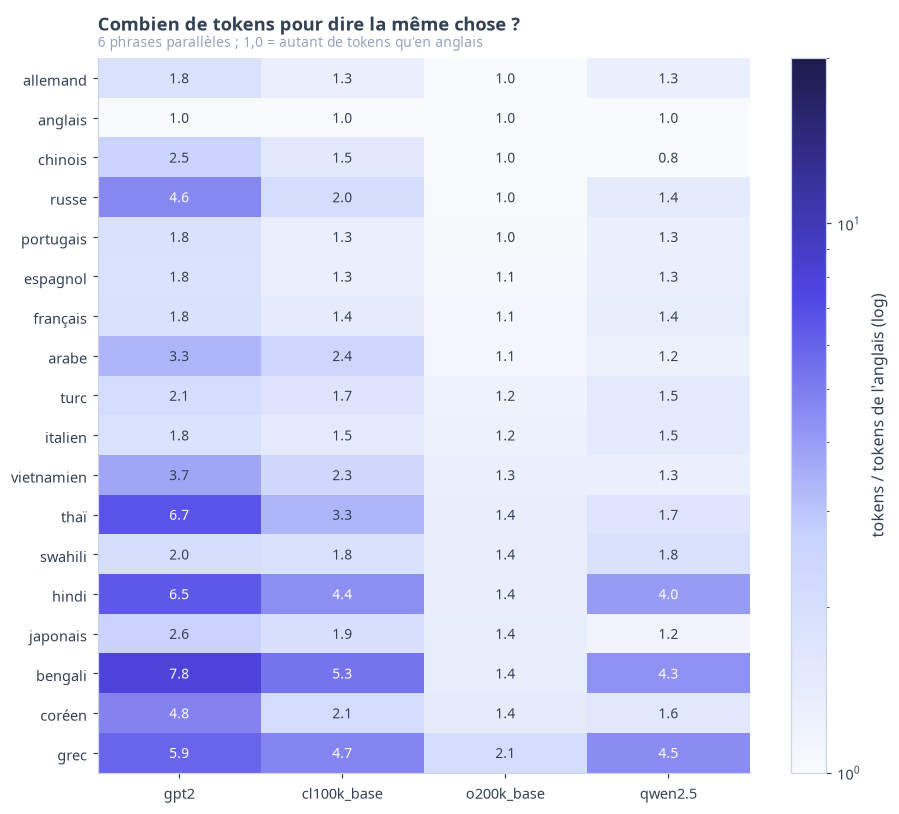

In [4]:
qwen_tok = AutoTokenizer.from_pretrained(llm.SMALL)
encoders = {name: tiktoken.get_encoding(name).encode for name in ["gpt2", "cl100k_base", "o200k_base"]}
encoders["qwen2.5"] = lambda s: qwen_tok(s, add_special_tokens=False)["input_ids"]
fert = m.tokens_per_language(encoders)
pivot = fert.pivot(index="langue", columns="tokenizer", values="ratio_vs_en")
pivot = pivot[["gpt2", "cl100k_base", "o200k_base", "qwen2.5"]].sort_values("o200k_base")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(pivot.values, cmap="aie_seq", aspect="auto", norm=plt.matplotlib.colors.LogNorm(1, 20))
ax.set_xticks(range(4), pivot.columns); ax.set_yticks(range(len(pivot)), pivot.index)
ax.grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9,
                color="white" if v > 4 else SLATE)
plt.colorbar(im, ax=ax, label="tokens / tokens de l'anglais (log)")
ax.set_title("Combien de tokens pour dire la même chose ?", pad=18)
subtitle(ax, "6 phrases parallèles ; 1,0 = autant de tokens qu'en anglais")
plt.tight_layout(); plt.show()

Trois constats :

1. **Le tokenizer de GPT-2** (entraîné sur un web anglophone) est très inefficace hors de
   l'alphabet latin : une phrase en hindi, bengali ou thaï coûte 6 à 8 fois plus de
   tokens qu'en anglais (le livre rapporte jusqu'à 10 fois pour le birman avec GPT-4). La raison est mécanique : ce tokenizer travaille sur les
   **octets** UTF-8 ; un caractère devanagari occupe 3 octets, et faute de fusions
   apprises pour ces séquences, chaque octet devient presque un token.
2. **Les vocabulaires plus grands et plus multilingues** réduisent l'écart, mais pas
   uniformément : `o200k_base` (GPT-4o) ramène presque toutes nos langues sous 1,5,
   tandis que Qwen2.5, très efficace en chinois (0,8 : moins de tokens qu'en anglais !),
   reste à environ 4 pour le hindi, le bengali et le grec. Un tokenizer reflète les
   priorités linguistiques de ses concepteurs.
3. Le **français** coûte de 10 % (`o200k_base`) à 80 % (GPT-2) de tokens de plus que
   l'anglais : la pénalité existe même pour une langue bien dotée.

Vérifions l'explication par les octets : nombre moyen d'octets UTF-8 par caractère et de
tokens GPT-2 par caractère, selon l'écriture.

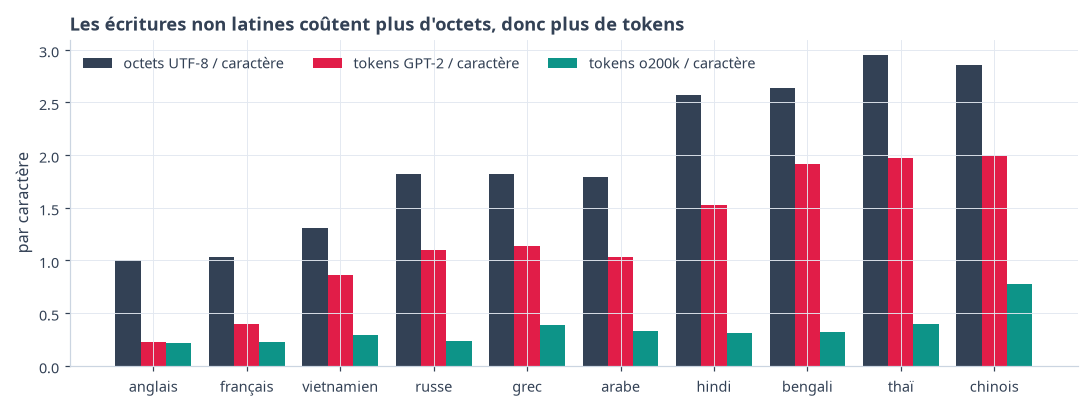

In [5]:
gpt2_enc = encoders["gpt2"]
rows = []
for code in ["en", "fr", "vi", "ru", "el", "ar", "hi", "bn", "th", "zh"]:
    txt = " ".join(m.PARALLEL_CORPUS[code])
    rows.append(dict(langue=m.LANG_NAMES[code], octets_par_car=len(txt.encode()) / len(txt),
                     tokens_gpt2_par_car=len(gpt2_enc(txt)) / len(txt),
                     tokens_o200k_par_car=len(encoders["o200k_base"](txt)) / len(txt)))
bytes_df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(bytes_df))
ax.bar(x - 0.27, bytes_df.octets_par_car, 0.27, color=SLATE, label="octets UTF-8 / caractère")
ax.bar(x, bytes_df.tokens_gpt2_par_car, 0.27, color=ROSE, label="tokens GPT-2 / caractère")
ax.bar(x + 0.27, bytes_df.tokens_o200k_par_car, 0.27, color=TEAL, label="tokens o200k / caractère")
ax.set_xticks(x, bytes_df.langue); ax.set_ylabel("par caractère")
ax.set_title("Les écritures non latines coûtent plus d'octets, donc plus de tokens")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

Le nombre de tokens GPT-2 par caractère suit de près le nombre d'octets par caractère :
pour les écritures que son vocabulaire n'a pas « vues », le tokenizer retombe presque
au niveau de l'octet.

**Traduisons en coût et en latence.** Supposons une application qui traite chaque jour
100 000 requêtes de 500 tokens (comptés en anglais) à 2,50 \$ par million de tokens en
entrée, et qui génère des réponses de 300 tokens à 50 tokens par seconde. Avec le ratio
$r_\ell$ mesuré pour le tokenizer de Qwen2.5 (le modèle ouvert utilisé dans ce cours) :
$$\text{coût}_\ell = r_\ell \times \text{coût}_{\text{en}}, \qquad
\text{latence}_\ell \approx r_\ell \times \frac{300}{50}\ \text{s}.$$

In [6]:
sel = ["chinois", "anglais", "espagnol", "français", "arabe", "vietnamien", "hindi", "bengali", "grec"]
rq = fert[fert.tokenizer == "qwen2.5"].set_index("langue")["ratio_vs_en"].loc[sel]
cost_en = 100_000 * 500 / 1e6 * 2.50
tab = pd.DataFrame({"ratio de tokens": rq, "coût entrée / jour ($)": rq * cost_en,
                    "latence réponse (s)": rq * 300 / 50,
                    "contexte 8k utile (équiv. tokens anglais)": 8192 / rq})
tab.round(1)

,ratio de tokens,coût entrée / jour ($),latence réponse (s),contexte 8k utile (équiv. tokens anglais)
langue,,,,
chinois,0.8,96.2,4.6,10649.6
anglais,1.0,125.0,6.0,8192.0
espagnol,1.3,163.5,7.8,6264.5
français,1.4,173.1,8.3,5916.4
arabe,1.2,156.2,7.5,6553.6
vietnamien,1.3,161.1,7.7,6358.0
hindi,4.0,502.4,24.1,2038.2
bengali,4.3,543.3,26.1,1884.9
grec,4.5,557.7,26.8,1836.1


Pour le même service, une langue à ratio 4 coûte quatre fois plus cher, répond quatre
fois plus lentement et « voit » quatre fois moins de contenu dans la même fenêtre de
contexte ; plus généralement, une langue à ratio 2 coûte deux fois plus cher, répond deux fois
plus lentement et « voit » deux fois moins de contenu dans la même fenêtre de contexte.
C'est l'une des raisons pour lesquelles on entraîne des modèles centrés sur une langue
(le livre cite CroissantLLM pour le français, PhoGPT pour le vietnamien, Jais pour
l'arabe), avec un tokenizer adapté.

> **À retenir.** Le nombre de tokens pour un même contenu varie d'un facteur 1 à plus
> de 10 selon la langue et le tokenizer. Coût, latence et contexte utile en dépendent
> directement : mesurez-le sur vos propres données avant de choisir un modèle.